# CIENCIA DE DATOS
*Ilaquita Pariapaza Kemelly Shanell*

In [1]:
import pandas as pd
import numpy as np

# 1. Cargar
df = pd.read_csv("21 Puno EPEN Anual 2024.csv", low_memory=False)
print("Base completa:", df.shape)

# 2. Convertir celdas vacías (' ') en NaN
df = df.replace(r"^\s*$", np.nan, regex=True)

# 3. Filtrar solo ocupados
df = df[pd.to_numeric(df["OCUP300"], errors="coerce") == 1].copy()
print("Solo ocupados:", df.shape)

# 4. Crear la variable objetivo: 1 = informal, 0 = formal
df["Informal_P"] = pd.to_numeric(df["Informal_P"], errors="coerce")
df["y"] = (df["Informal_P"] == 1).astype(int)

# 5. Revisar el balance de clases
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True).round(3))

Base completa: (19846, 131)
Solo ocupados: (8464, 131)
y
1    6660
0    1804
Name: count, dtype: int64
y
1    0.787
0    0.213
Name: proportion, dtype: float64


In [2]:
# Variables a eliminar
fuga = ["C310","C311","C312","C313","C317","C317A","SEGURO1","Informal_P"] \
     + [c for c in df.columns if c.startswith(("C361_","C362_","C364_","C365_"))]
ids = ["LLAVE_PANEL","CONGLOMERADO","SELVIV","HOGAR","MUESTRA",
       "C201","C300n","NROINF","FAC300_ANUAL"]
fechas = ["ANIO","MES","C301_DIA","C301_MES","C301_ANIO"]
otros = ["CCDD","OCUP300","RESIDENT"]

# Construir X
X = df.drop(columns=["y"] + [c for c in fuga+ids+fechas+otros if c in df.columns]).copy()
X = X.apply(pd.to_numeric, errors="coerce")

# Quitar constantes
const = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=const)

# Quitar columnas con más de 50% de vacíos
na = X.isna().mean()
X = X.drop(columns=na[na > 0.5].index)

y = df["y"]

print(X.shape)
print(list(X.columns))
print(X.isna().mean()[X.isna().mean() > 0].round(3))

(8464, 36)
['ESTRATO', 'AREA', 'C203', 'C204', 'C207', 'C208', 'C303', 'C308_COD', 'C309_COD', 'C318_1', 'C318_2', 'C318_3', 'C318_4', 'C318_5', 'C318_6', 'C318_7', 'C318_T', 'whoraT', 'C330', 'C333', 'P209H', 'C335', 'C359', 'C366', 'C366_1', 'C375_1', 'C375_2', 'C375_3', 'C375_4', 'C375_5', 'C375_6', 'C376', 'C377', 'INGTOT', 'INGTOTP', 'ingtrabw']
C335      0.100
C366_1    0.084
dtype: float64


In [3]:
from sklearn.model_selection import train_test_split

# 1. Reducir los códigos de ocupación y rama
cod_ocup = df["C308_COD"].astype(str).str.strip().str.zfill(4)
cod_rama = df["C309_COD"].astype(str).str.strip().str.zfill(4)

X = X.drop(columns=["C308_COD", "C309_COD"])
X["OCUP_GRUPO"] = cod_ocup.str[0]
X["RAMA_DIV"]   = cod_rama.str[:2]

# 2. Variables nominales como texto (categóricas)
nominales = ["C203", "C376", "C377", "OCUP_GRUPO", "RAMA_DIV"]
for c in nominales:
    X[c] = X[c].astype(str)

# 3. División entrenamiento / prueba (estratificada)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123, stratify=y
)

# 4. Rellenar vacíos con la mediana del entrenamiento
num = X_train.select_dtypes("number").columns
med = X_train[num].median()
X_train = X_train.copy()
X_test  = X_test.copy()
X_train[num] = X_train[num].fillna(med)
X_test[num]  = X_test[num].fillna(med)

# 5. Verificación
print(X.shape, X_train.shape, X_test.shape)
print("Vacíos train/test:", X_train.isna().sum().sum(), X_test.isna().sum().sum())
print("% informales train/test:", y_train.mean().round(3), y_test.mean().round(3))

(8464, 36) (5924, 36) (2540, 36)
Vacíos train/test: 0 0
% informales train/test: 0.787 0.787


In [4]:
!pip install lazypredict -q

from lazypredict.Supervised import LazyClassifier

clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None, random_state=123)
models, predictions = clf.fit(X_train, X_test, y_train, y_test)
models

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
LGBMClassifier,0.914961,0.848230,0.955231,0.912612,0.912569,0.914961,0.413504
XGBClassifier,0.915354,0.847806,0.953446,0.912911,0.912978,0.915354,0.506453
BaggingClassifier,0.912992,0.847653,0.919867,0.910837,0.910546,0.912992,0.910863
CalibratedClassifierCV,0.920079,0.847437,0.953672,0.917020,0.918299,0.920079,0.928559
LinearSVC,0.921260,0.844817,0.954171,0.917787,0.919996,0.921260,0.371552
RandomForestClassifier,0.917323,0.841642,0.951492,0.913975,0.915414,0.917323,1.711322
ExtraTreesClassifier,0.913386,0.837118,0.949854,0.910033,0.911030,0.913386,1.038173
AdaBoostClassifier,0.901969,0.832561,0.934947,0.899698,0.899019,0.901969,1.049607
LogisticRegression,0.903150,0.825222,0.942461,0.899822,0.899871,0.903150,0.313578


In [5]:
!pip install memory_profiler -q

import pickle, time, pandas as pd
from memory_profiler import memory_usage
from sklearn.base import clone

pipes = clf.provide_models(X_train, X_test, y_train, y_test)  # dict {nombre: Pipeline entrenado}

candidatos = ["LGBMClassifier", "XGBClassifier", "BaggingClassifier",
              "CalibratedClassifierCV", "LinearSVC"]

filas = []
for nombre in candidatos:
    pipe = pipes[nombre]

    # ESPACIO: tamaño del modelo entrenado (KB)
    espacio_kb = len(pickle.dumps(pipe)) / 1024

    # MEMORIA: pico de RAM durante el entrenamiento (MB)
    base = memory_usage(-1, interval=0.05, timeout=0.2)[0]       # RAM antes de entrenar
    pico = max(memory_usage((clone(pipe).fit, (X_train, y_train)), interval=0.05))
    memoria_mb = pico - base                                      # memoria extra usada por el fit

    # TIEMPO de predicción (s)
    t0 = time.perf_counter()
    pipe.predict(X_test)
    t_pred = time.perf_counter() - t0

    filas.append([nombre, round(espacio_kb, 1), round(memoria_mb, 1), round(t_pred, 4)])

recursos = pd.DataFrame(filas, columns=["Model", "Espacio (KB)", "Memoria pico fit (MB)", "Tiempo predict (s)"])

tabla_final = models.loc[candidatos].reset_index().merge(recursos, on="Model")
tabla_final[["Model", "Balanced Accuracy", "ROC AUC", "F1 Score", "Time Taken",
             "Espacio (KB)", "Memoria pico fit (MB)", "Tiempo predict (s)"]]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Balanced Accuracy,ROC AUC,F1 Score,Time Taken,Espacio (KB),Memoria pico fit (MB),Tiempo predict (s)
0,LGBMClassifier,0.848230,0.955231,0.912612,0.413504,347.8,0.0,0.0488
1,XGBClassifier,0.847806,0.953446,0.912911,0.506453,253.4,0.4,0.0290
2,BaggingClassifier,0.847653,0.919867,0.910837,0.910863,560.2,0.0,0.0339
3,CalibratedClassifierCV,0.847437,0.953672,0.917020,0.928559,10.3,0.0,0.0868
4,LinearSVC,0.844817,0.954171,0.917787,0.371552,6.4,0.0,0.0359


In [7]:
import numpy as np

X_big = pd.concat([X_train] * 30, ignore_index=True)   # 30 veces más filas
y_big = pd.concat([y_train] * 30, ignore_index=True)

filas = []
for nombre in candidatos:
    base = memory_usage(-1, interval=0.05, timeout=0.2)[0]
    pico = max(memory_usage((clone(pipes[nombre]).fit, (X_big, y_big)), interval=0.05))
    filas.append([nombre, round(pico - base, 1)])

pd.DataFrame(filas, columns=["Model", "Memoria pico fit, n×30 (MB)"])

,Model,"Memoria pico fit, n×30 (MB)"
0,LGBMClassifier,154.1
1,XGBClassifier,168.1
2,BaggingClassifier,177.6
3,CalibratedClassifierCV,243.2
4,LinearSVC,192.1


Validación cruzada

In [8]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
filas = []
for nombre in candidatos:
    r = cross_validate(clone(pipes[nombre]), X, y, cv=cv,
                       scoring=["balanced_accuracy", "roc_auc", "f1_weighted"])
    filas.append([nombre,
                  f"{r['test_balanced_accuracy'].mean():.3f} ± {r['test_balanced_accuracy'].std():.3f}",
                  f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                  f"{r['test_f1_weighted'].mean():.3f} ± {r['test_f1_weighted'].std():.3f}"])
pd.DataFrame(filas, columns=["Model", "Bal. Acc.", "ROC AUC", "F1"])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Model,Bal. Acc.,ROC AUC,F1
0,LGBMClassifier,0.853 ± 0.009,0.950 ± 0.002,0.915 ± 0.005
1,XGBClassifier,0.851 ± 0.011,0.948 ± 0.003,0.912 ± 0.007
2,BaggingClassifier,0.848 ± 0.008,0.919 ± 0.005,0.902 ± 0.006
3,CalibratedClassifierCV,0.843 ± 0.008,0.947 ± 0.003,0.913 ± 0.003
4,LinearSVC,0.838 ± 0.012,0.947 ± 0.003,0.913 ± 0.004


Importancia de variables y descarte de fuga

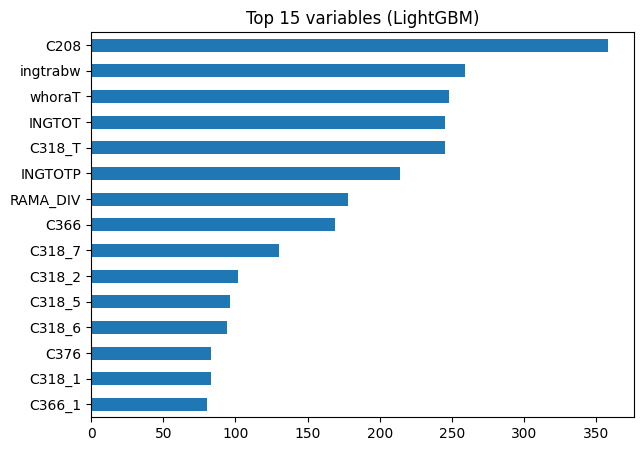

In [9]:
import lightgbm as lgb
import matplotlib.pyplot as plt

Xl = X_train.copy()
for c in nominales:
    Xl[c] = Xl[c].astype("category")
m = lgb.LGBMClassifier(random_state=123, verbose=-1).fit(Xl, y_train)

imp = pd.Series(m.feature_importances_, index=Xl.columns).sort_values().tail(15)
imp.plot.barh(figsize=(7, 5), title="Top 15 variables (LightGBM)")
plt.show()

Matriz de confusión y análisis del error

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


              precision    recall  f1-score   support

  Formal (0)      0.848     0.732     0.786       541
Informal (1)      0.930     0.964     0.947      1999

    accuracy                          0.915      2540
   macro avg      0.889     0.848     0.866      2540
weighted avg      0.913     0.915     0.913      2540



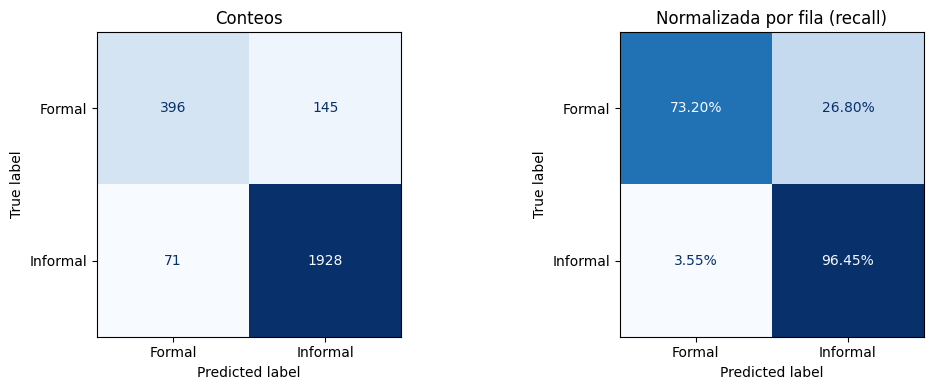

Formales bien clasificados (TN): 396
Formales marcados como informales (FP): 145  -> 26.8% de los formales
Informales marcados como formales (FN): 71  -> 3.6% de los informales
Informales bien clasificados (TP): 1928

Tasa de error por AREA
         n  tasa_error
AREA                  
1     2138       0.099
2      402       0.010

Tasa de error por OCUP_GRUPO
              n  tasa_error
OCUP_GRUPO                 
3           143       0.273
4            75       0.200
2           282       0.131
5           440       0.114
7           282       0.099
8           192       0.083
9           810       0.038
0            14       0.000
1            13       0.000
6           289       0.000

Tasa de error por C203
         n  tasa_error
C203                  
7       13       0.154
1     1461       0.092
2      633       0.081
3      409       0.068
11       3       0.000
4        3       0.000
5        4       0.000
6        9       0.000
8        5       0.000


In [10]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, balanced_accuracy_score)

# 1. Predicciones del modelo elegido
mejor = pipes["LGBMClassifier"]
y_pred = mejor.predict(X_test)

# 2. Reporte por clase
print(classification_report(y_test, y_pred, target_names=["Formal (0)", "Informal (1)"], digits=3))

# 3. Matriz de confusión: conteos y normalizada por fila (= recall de cada clase)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Formal", "Informal"],
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Conteos")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Formal", "Informal"],
                                        normalize="true", values_format=".2%",
                                        cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title("Normalizada por fila (recall)")
plt.tight_layout(); plt.show()

# 4. Tipos de error en números
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Formales bien clasificados (TN): {tn}")
print(f"Formales marcados como informales (FP): {fp}  -> {fp/(tn+fp):.1%} de los formales")
print(f"Informales marcados como formales (FN): {fn}  -> {fn/(fn+tp):.1%} de los informales")
print(f"Informales bien clasificados (TP): {tp}")

# 5. Análisis del error: ¿en qué perfiles falla más?
an = X_test.copy()
an["real"] = y_test.values
an["pred"] = y_pred
an["error"] = (an["real"] != an["pred"]).astype(int)

for var in ["AREA", "OCUP_GRUPO", "C203"]:
    t = an.groupby(var).agg(n=("error", "size"), tasa_error=("error", "mean"))
    print(f"\nTasa de error por {var}")
    print(t.sort_values("tasa_error", ascending=False).round(3))